# Day 14 - Triton Vector Addition

In [1]:
pip install triton torch

In [3]:
import torch

import triton
import triton.language as tl

DEVICE = triton.runtime.driver.active.get_active_torch_device()

@triton.jit
def add_kernel(x_ptr, y_ptr, output_ptr, size, BLOCKSIZE: tl.constexpr):
  pid = tl.program_id(axis = 0)

  block_start = BLOCKSIZE * pid
  offsets = block_start + tl.arange(0, BLOCKSIZE)

  mask = offsets < size

  x = tl.load(x_ptr + offsets, mask=mask)
  y = tl.load(y_ptr + offsets, mask=mask)

  output = x + y

  tl.store(output_ptr + offsets, output, mask=mask)

In [4]:
def add(x: torch.Tensor, y: torch.Tensor, blocksize: int = 1024):
  output = torch.empty_like(x)

  assert (x.device == DEVICE and y.device == DEVICE and output.device == DEVICE)

  size = output.numel()

  grid = lambda meta: (triton.cdiv(size, meta['BLOCKSIZE']),)

  add_kernel[grid](x, y, output, size, BLOCKSIZE= blocksize)

  return output

In [5]:
torch.manual_seed(67)

size = 1000003

x = torch.rand(size, device=DEVICE)
y = torch.rand(size, device=DEVICE)

output_torch = x + y
output_triton = add(x, y)

print(output_torch)
print(output_triton)
print(torch.allclose(output_torch, output_triton))
print(f"max diff: {(output_torch - output_triton).abs().max().item()}")

tensor([0.5811, 1.2244, 1.5902,  ..., 0.2518, 1.9003, 0.5927], device='cuda:0')
tensor([0.5811, 1.2244, 1.5902,  ..., 0.2518, 1.9003, 0.5927], device='cuda:0')
True
max diff: 0.0


In [7]:
DTYPES = {'fp16': torch.float16, 'bf16': torch.bfloat16, 'fp32': torch.float32}

def make_bench(name, configs, xs=range(12, 28)):

    line_vals = [f"{impl}-{dt}-{bs}" for dt, impl, bs, *_ in configs]
    line_names = [c[3] for c in configs]
    styles = [(c[4], c[5]) for c in configs]

    @triton.testing.perf_report(
        triton.testing.Benchmark(
            x_names=['size'],
            x_vals=[2**i for i in xs],
            x_log=True,
            line_arg='provider',
            line_vals=line_vals,
            line_names=line_names,
            styles=styles,
            ylabel='GB/s',
            plot_name=name,
            args={},
        )
    )

    def bench(size, provider):
        impl, dt, bs = provider.split('-')

        x = torch.rand(size, device=DEVICE, dtype=DTYPES[dt])
        y = torch.rand(size, device=DEVICE, dtype=DTYPES[dt])

        fn = (lambda: x + y) if impl == 'torch' else (lambda: add(x, y, blocksize=int(bs)))
        ms = triton.testing.do_bench(fn)

        return 3 * x.numel() * x.element_size() * 1e-9 / (ms * 1e-3)

    return bench

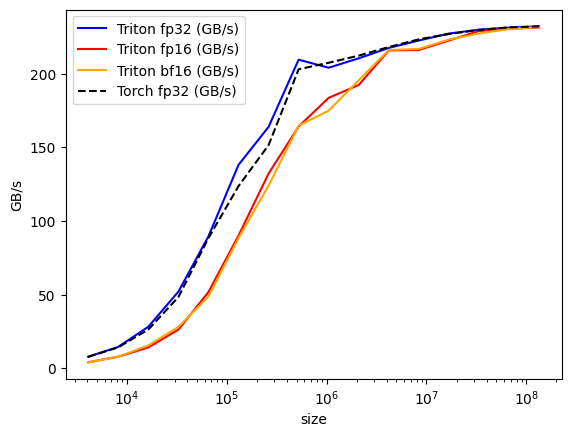

dtype-comparison:
           size  Triton fp32 (GB/s)  Triton fp16 (GB/s)  Triton bf16 (GB/s)  Torch fp32 (GB/s)
0        4096.0            7.918376            4.174149            4.122267           7.796954
1        8192.0           14.584442            7.931153            7.902946          14.291834
2       16384.0           28.265874           14.222222           15.593084          26.366741
3       32768.0           52.063200           26.297383           28.093546          48.385890
4       65536.0           89.584446           51.811282           48.822448          88.392940
5      131072.0          138.059250           90.074073           88.426314         123.667566
6      262144.0          163.848626          132.158948          123.989377         151.445392
7      524288.0          209.408661          164.116409          164.686548         202.922341
8     1048576.0          203.981599          183.553956          174.855259         207.339529
9     2097152.0          210.362

In [8]:
make_bench('dtype-comparison', [
    ('fp32', 'triton', 1024, 'Triton fp32', 'blue',   '-'),
    ('fp16', 'triton', 1024, 'Triton fp16', 'red',    '-'),
    ('bf16', 'triton', 1024, 'Triton bf16', 'orange', '-'),
    ('fp32', 'torch',  0,    'Torch fp32',  'black',  '--'),
]).run(print_data=True, show_plots=True)

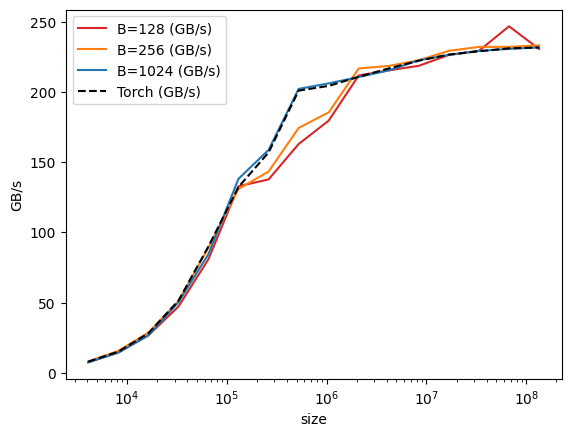

blocksize-comparison:
           size  B=128 (GB/s)  B=256 (GB/s)  B=1024 (GB/s)  Torch (GB/s)
0        4096.0      7.390974      7.916675       7.361022      7.860966
1        8192.0     14.265564     15.541315      14.333511     14.964835
2       16384.0     26.557882     28.533888      26.520863     28.053460
3       32768.0     47.093616     50.974332      50.159367     51.273438
4       65536.0     80.930844     89.262456      84.556518     90.021977
5      131072.0    132.994587    131.108801     138.325087    132.488893
6      262144.0    137.851386    143.474213     158.883939    157.064199
7      524288.0    163.113590    174.577448     202.431128    201.232058
8     1048576.0    179.805110    185.718949     206.417361    204.617308
9     2097152.0    212.091268    217.047235     210.921571    211.113562
10    4194304.0    215.651531    218.846549     215.702070    217.084722
11    8388608.0    218.961929    222.895298     222.881156    222.610200
12   16777216.0    226.697612

In [9]:
make_bench('blocksize-comparison', [
    ('fp32', 'triton', 128,  'B=128',  'tab:red',    '-'),
    ('fp32', 'triton', 256,  'B=256',  'tab:orange', '-'),
    ('fp32', 'triton', 1024, 'B=1024', 'tab:blue',   '-'),
    ('fp32', 'torch',  0,    'Torch',   'black',      '--'),
]).run(print_data=True, show_plots=True)